# 03 · Calendar: Lịch 365 ngày của từng listing

Calendar là bảng có nhiều dòng nhất, vì mỗi listing có một dòng cho mỗi ngày trong năm tới. Với hiệp hội du lịch, đây là nguồn chính để
trả lời câu hỏi có bao nhiêu ngày được mở cho khách đặt, vào thời gian nào và ở khu vực nào. Tuy vậy, cột `available` rất dễ bị hiểu rộng hơn những gì nó thật sự cho biết, nên
phần lớn notebook này dành để hiểu đúng cột đó.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

TEN_CAU_HINH = "london.yaml"   # Đổi file cấu hình ở đây nếu khảo sát thành phố/mốc khác.


def tim_thu_muc_du_an(thu_muc_bat_dau: Path) -> Path:
    """Đi ngược lên các thư mục cha cho tới khi gặp configs/<TEN_CAU_HINH>."""
    # Vòng lặp qua các thư mục cha (vài cấp), không phải qua dòng dữ liệu.
    for thu_muc in [thu_muc_bat_dau, *thu_muc_bat_dau.parents]:
        if (thu_muc / "configs" / TEN_CAU_HINH).is_file():
            return thu_muc

    raise FileNotFoundError(f"Không tìm thấy thư mục dự án chứa configs/{TEN_CAU_HINH}")


THU_MUC_DU_AN = tim_thu_muc_du_an(Path.cwd().resolve())

with (THU_MUC_DU_AN / "configs" / TEN_CAU_HINH).open("r", encoding="utf-8-sig") as f:
    cau_hinh = yaml.safe_load(f)

thanh_pho = cau_hinh["city"]
snapshots = [str(snapshot) for snapshot in cau_hinh["snapshots"]]   # YAML đọc ngày không nháy thành date
moc_gia = max(snapshots)   # Quy tắc của nhóm: chỉ mốc cuối được dùng giá
THU_MUC_RAW = THU_MUC_DU_AN / "data" / "raw" / thanh_pho
THU_MUC_PHAN_CONG = THU_MUC_DU_AN / "data" / "assignment"

phan_cong_listings = pd.read_csv(THU_MUC_PHAN_CONG / "listings.csv", dtype=str, keep_default_na=False)
phan_cong_reviews = pd.read_csv(THU_MUC_PHAN_CONG / "reviews.csv", dtype=str, keep_default_na=False)
phan_cong_vung = pd.read_csv(THU_MUC_PHAN_CONG / "areas.csv", dtype={"analysis_area": str}, keep_default_na=False)
cac_listing_id = set(phan_cong_listings["listing_id"])
cac_review_id = set(phan_cong_reviews["review_id"])

print("Thư mục dự án :", THU_MUC_DU_AN.name)
print("Thành phố     :", thanh_pho, "| tiền tệ:", cau_hinh["currency"])
print("Các mốc       :", snapshots, "| mốc dùng giá:", moc_gia)
print("Phân công     :", len(cac_listing_id), "listing,", len(cac_review_id), "review")

Thư mục dự án : 2627-LTXLDL-Airbnb-dse2049_7-nhom15
Thành phố     : london | tiền tệ: GBP
Các mốc       : ['2025-09-14', '2025-12-13', '2026-03-21', '2026-06-19'] | mốc dùng giá: 2026-06-19
Phân công     : 1000 listing, 5000 review


## 1. Lọc calendar của nhóm

Ba file calendar có từ 33,9 đến 35,4 triệu dòng, riêng mốc 2026-03-21 chỉ có khoảng 19,6 triệu dòng. Ô dưới đây đọc file theo từng khối 500 nghìn dòng
và chỉ giữ những dòng có `listing_id` thuộc nhóm. Ô này chạy mất khoảng một phút.

In [2]:
lich_nhom: dict[str, pd.DataFrame] = {}
thong_tin_doc: dict[str, dict] = {}

# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    cac_khoi_da_loc = []
    so_dong_thanh_pho = 0
    with pd.read_csv(THU_MUC_RAW / snapshot / "calendar.csv.gz", dtype=str, keep_default_na=False, chunksize=500_000) as cac_khoi:
        # Vòng lặp qua các khối 500 nghìn dòng: cả file 35 triệu dòng không nên nạp vào bộ nhớ một lần (Bài 6).
        for khoi in cac_khoi:
            so_dong_thanh_pho += len(khoi)
            cac_khoi_da_loc.append(khoi.loc[khoi["listing_id"].isin(cac_listing_id)])

    lich_nhom[snapshot] = pd.concat(cac_khoi_da_loc, ignore_index=True)
    thong_tin_doc[snapshot] = {"dong_thanh_pho": so_dong_thanh_pho, "dong_cua_nhom": len(lich_nhom[snapshot]),
                               "cac_cot": ", ".join(khoi.columns)}
    print(f"[ĐÃ LỌC] {snapshot}: {len(lich_nhom[snapshot]):,} / {so_dong_thanh_pho:,} dòng", flush=True)

pd.DataFrame(thong_tin_doc).T

[ĐÃ LỌC] 2025-09-14: 365,000 / 35,357,974 dòng


[ĐÃ LỌC] 2025-12-13: 365,000 / 34,928,339 dòng


[ĐÃ LỌC] 2026-03-21: 365,000 / 19,612,946 dòng


[ĐÃ LỌC] 2026-06-19: 365,000 / 33,871,636 dòng


,dong_thanh_pho,dong_cua_nhom,cac_cot
2025-09-14,35357974,365000,"listing_id, date, available, price, adjusted_price, minimum_nights, maximum_..."
2025-12-13,34928339,365000,"listing_id, date, available, minimum_nights, maximum_nights"
2026-03-21,19612946,365000,"listing_id, date, available, minimum_nights, maximum_nights"
2026-06-19,33871636,365000,"listing_id, date, available, minimum_nights, maximum_nights"


Mỗi mốc cho đúng 365.000 dòng, bằng 1.000 listing nhân 365 ngày. Riêng mốc đầu có thêm hai cột `price` và `adjusted_price`, còn ba mốc sau
thì không có. Ô tiếp theo xem nội dung của hai cột này và xác nhận rằng cặp `(listing_id, date)` không bị trùng.

In [3]:
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    so_ngay = lich.groupby("listing_id")["date"].nunique()
    print(f"{snapshot}: listing = {lich['listing_id'].nunique()}, ngày/listing min–max = {so_ngay.min()}–{so_ngay.max()}, "
          f"trùng (listing_id, date) = {lich.duplicated(['listing_id', 'date']).sum()}, "
          f"available = {lich['available'].value_counts().to_dict()}")

lich_dau = lich_nhom[snapshots[0]]
for cot in ("price", "adjusted_price"):
    if cot in lich_dau:
        print(f"Cột {cot} ở mốc {snapshots[0]}: {lich_dau[cot].eq('').mean():.0%} ô rỗng")

2025-09-14: listing = 1000, ngày/listing min–max = 365–365, trùng (listing_id, date) = 0, available = {'t': 217702, 'f': 147298}


2025-12-13: listing = 1000, ngày/listing min–max = 365–365, trùng (listing_id, date) = 0, available = {'t': 222881, 'f': 142119}


2026-03-21: listing = 1000, ngày/listing min–max = 365–365, trùng (listing_id, date) = 0, available = {'t': 214144, 'f': 150856}


2026-06-19: listing = 1000, ngày/listing min–max = 365–365, trùng (listing_id, date) = 0, available = {'t': 215553, 'f': 149447}
Cột price ở mốc 2025-09-14: 100% ô rỗng
Cột adjusted_price ở mốc 2025-09-14: 100% ô rỗng


Cặp `(listing_id, date)` xác định duy nhất từng dòng, nên bảng không có dòng trùng. Mỗi listing có đủ 365 ngày, không ngày nào bị lặp, và cột `available` chỉ chứa `t` hoặc `f`. Còn hai cột giá
ở mốc đầu thì rỗng toàn bộ. Như vậy calendar không chứa thông tin giá ở bất kỳ mốc nào, nên cũng không có cách nào lấy giá theo thời gian
từ bảng này.

## 2. Ngày bắt đầu của lịch 365 ngày

In [4]:
cac_dong = []
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    ngay_bat_dau = pd.to_datetime(lich.groupby("listing_id")["date"].min())
    ngay_cao_listings = pd.read_csv(
        THU_MUC_RAW / snapshot / "listings.csv.gz",
        usecols=["id", "last_scraped"],
        dtype=str,
    ).set_index("id")["last_scraped"]
    ngay_cao = pd.to_datetime(ngay_cao_listings.loc[ngay_bat_dau.index])
    cac_dong.append({
        "snapshot": snapshot,
        "bat_dau_som_nhat": ngay_bat_dau.min().date(),
        "bat_dau_muon_nhat": ngay_bat_dau.max().date(),
        "ket_thuc_muon_nhat": pd.to_datetime(lich["date"]).max().date(),
        "bat_dau_trung_last_scraped": f"{(ngay_bat_dau == ngay_cao).mean():.0%}",
    })
pd.DataFrame(cac_dong).set_index("snapshot")

,bat_dau_som_nhat,bat_dau_muon_nhat,ket_thuc_muon_nhat,bat_dau_trung_last_scraped
snapshot,,,,
2025-09-14,2025-09-14,2025-09-18,2026-09-17,100%
2025-12-13,2025-12-13,2026-01-02,2027-01-01,100%
2026-03-21,2026-03-21,2026-04-02,2027-04-01,98%
2026-06-19,2026-06-19,2026-07-01,2027-06-30,100%


Lịch của gần như mọi listing (98–100%) bắt đầu đúng vào ngày listing đó được cào, tức ngày ghi trong `last_scraped`, chứ không phải ngày
chụp. Ở mốc 2025-12-13, ngày bắt đầu của các listing cách nhau tới 20 ngày. Do đó, khi tính tỷ lệ ngày được ghi là sẵn có theo tháng dương lịch,
không thể giả định tháng nào cũng có đủ 1.000 listing nhân số ngày của tháng. Tháng đầu và tháng cuối của mỗi mốc chắc chắn chỉ được phủ một phần,
còn các tháng khác cũng cần được kiểm tra độ phủ, vì lịch của một số listing bắt đầu muộn sang tháng kế tiếp. Mục 3 đếm số dòng của từng tháng để làm việc này.

Ta cũng có thể đối chiếu hai bảng với nhau. Ô dưới đếm số ngày mang `t` trong 30, 90 và 365 ngày tính từ ngày đầu lịch của từng listing,
rồi so với ba cột `availability_30`, `availability_90` và `availability_365` trong listings.

In [5]:
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    ngay = pd.to_datetime(lich["date"], format="%Y-%m-%d")
    so_ngay_tu_dau = (ngay - ngay.groupby(lich["listing_id"]).transform("min")).dt.days   # transform (Bài 5)
    trong = lich["available"].eq("t")
    dem_tu_lich = pd.DataFrame({
        "availability_30": trong.where(so_ngay_tu_dau < 30, False).groupby(lich["listing_id"]).sum(),
        "availability_90": trong.where(so_ngay_tu_dau < 90, False).groupby(lich["listing_id"]).sum(),
        "availability_365": trong.groupby(lich["listing_id"]).sum(),
    })
    tu_listings = (
        pd.read_csv(THU_MUC_RAW / snapshot / "listings.csv.gz", usecols=["id", *dem_tu_lich.columns], dtype=str)
        .set_index("id")
        .loc[dem_tu_lich.index]
        .apply(pd.to_numeric)   # apply theo CỘT (3 cột), không phải theo hàng
    )
    so_khop = tu_listings.eq(dem_tu_lich).sum()
    print(f"{snapshot}: " + ", ".join(f"{cot} khớp {so_khop[cot]}/1000" for cot in so_khop.index))

2025-09-14: availability_30 khớp 1000/1000, availability_90 khớp 1000/1000, availability_365 khớp 1000/1000


2025-12-13: availability_30 khớp 1000/1000, availability_90 khớp 1000/1000, availability_365 khớp 1000/1000


2026-03-21: availability_30 khớp 1000/1000, availability_90 khớp 1000/1000, availability_365 khớp 1000/1000


2026-06-19: availability_30 khớp 1000/1000, availability_90 khớp 1000/1000, availability_365 khớp 1000/1000


Cả ba cột khớp ở toàn bộ 1.000 listing của cả bốn mốc. Như vậy `availability_30`, `availability_90` và `availability_365` chỉ là số đếm tóm tắt từ
calendar, tính từ ngày đầu lịch của từng listing, không phải một nguồn độc lập. Khi cần KPI về số ngày sẵn có, ta có thể tính nhanh từ listings.
Calendar chỉ cần dùng khi muốn xem chi tiết theo ngày hay theo tháng.

## 3. Ý nghĩa của `available = f`

Cột `available` chỉ cho biết một ngày được ghi là sẵn có (`t`) hay không sẵn có (`f`). Một ngày `f` có thể là ngày đã có khách đặt, ngày chủ nhà
tự chặn lịch, hoặc ngày không thỏa quy tắc số đêm tối thiểu, và dữ liệu không phân biệt các trường hợp này. Vì vậy, tỷ lệ ngày `t` nên được gọi
đúng là tỷ lệ ngày được ghi là sẵn có, không nên gọi là tỷ lệ còn trống hay suy ra tỷ lệ lấp đầy. Biểu đồ dưới đây cho thấy vì sao cần cẩn thận.

**Cách đọc biểu đồ.** Mỗi đường là lịch nhìn từ một mốc chụp, và mỗi điểm trên đường là một tháng. Chiều cao của điểm là tỷ lệ listing-ngày được ghi là sẵn có trong tháng đó: Lấy mọi cặp (listing, ngày) thuộc tháng, rồi xem bao nhiêu phần trăm mang giá trị `t`. Điểm được đặt ở ngày cuối tháng, nên điểm nằm sát vạch của một tháng thực ra là số liệu của tháng liền trước.

Các đường bắt đầu muộn dần theo mốc chụp, vì lịch luôn bắt đầu từ ngày chụp và kéo dài 365 ngày. Điểm đầu và điểm cuối của mỗi đường thường chỉ phủ một phần tháng, nên không nên đặt chúng ngang hàng với các điểm ở giữa. Bảng ở ô ngay sau biểu đồ cho biết mỗi tháng được phủ bao nhiêu dòng. Chỗ hai đường chồng lên nhau là cùng một tháng được nhìn từ hai mốc khác nhau.

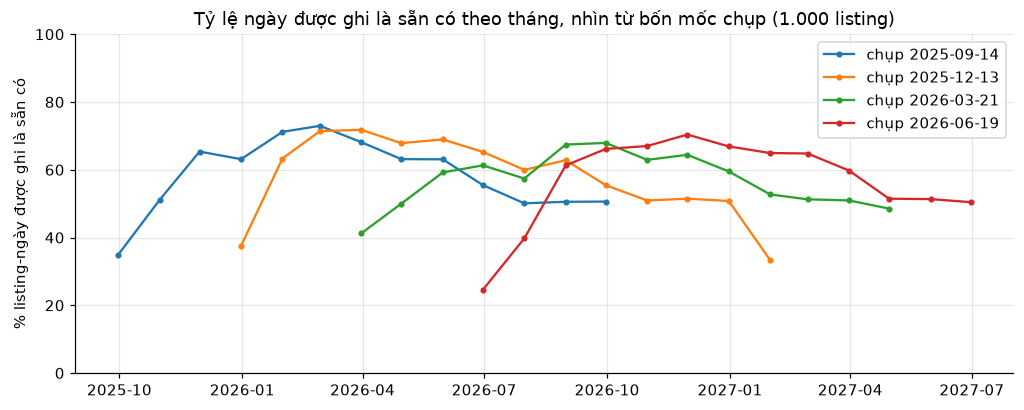

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
# Vòng lặp qua 4 mốc để vẽ mỗi mốc một đường; phép tính bên trong chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    ty_le_trong = (
        lich.assign(ngay=pd.to_datetime(lich["date"], format="%Y-%m-%d"), trong=lich["available"].eq("t"))
        .set_index("ngay")["trong"]
        .resample("ME")   # Gom theo tháng dương lịch, nhãn là ngày cuối tháng (Bài 8)
        .mean()
    )
    ax.plot(ty_le_trong.index, ty_le_trong * 100, marker="o", ms=3, label=f"chụp {snapshot}")

ax.set(ylim=(0, 100), ylabel="% listing-ngày được ghi là sẵn có",
       title="Tỷ lệ ngày được ghi là sẵn có theo tháng, nhìn từ bốn mốc chụp (1.000 listing)")
ax.legend()
plt.show()

Bốn đường có chung một hình dạng. Tỷ lệ ngày sẵn có thấp ở vài tuần đầu, tăng dần trong hai đến năm tháng tiếp theo, rồi đi ngang quanh mức 50%
ở phần xa nhất của lịch.

Dữ liệu chỉ cho thấy hình dạng này, không cho biết nguyên nhân. Phần đầu thấp có thể do khách đã đặt, cũng có thể do chủ nhà chặn những ngày gần.
Phần cuối đi ngang có thể do nhiều chủ nhà chưa mở lịch cho những tháng xa. Điều chắc chắn là không thể đọc `f` thành "đã có khách": Nếu đọc như vậy,
ta sẽ kết luận rằng một nửa số đêm đã kín khách cho tới gần một năm sau, một kết luận mà dữ liệu không hỗ trợ.

Các đường còn chồng lên nhau ở một số tháng, nghĩa là cùng một tháng được nhìn từ nhiều mốc chụp khác nhau. Ô dưới tính tỷ lệ ngày sẵn có của
những tháng mà cả bốn mốc đều thấy, kèm số dòng listing-ngày của từng ô để biết tháng đó có được phủ đầy đủ không.

In [7]:
cac_ty_le: dict[str, pd.Series] = {}
cac_so_dong: dict[str, pd.Series] = {}
# Mỗi mốc cho một cột của hai bảng; vòng lặp qua 4 mốc.
for snapshot, lich in lich_nhom.items():
    theo_thang = (
        lich.assign(ngay=pd.to_datetime(lich["date"], format="%Y-%m-%d"), trong=lich["available"].eq("t"))
        .set_index("ngay")["trong"]
        .resample("ME")   # Gom theo tháng dương lịch, nhãn là ngày cuối tháng (Bài 8)
    )
    cac_ty_le[snapshot] = theo_thang.mean() * 100
    cac_so_dong[snapshot] = theo_thang.size()

bang_thang = pd.DataFrame(cac_ty_le).round(1).dropna()   # Chỉ giữ các tháng mà cả bốn mốc đều thấy
bang_phu = pd.DataFrame(cac_so_dong).loc[bang_thang.index].astype("Int64")
# Một tháng được phủ đủ khi có đủ 1.000 listing × số ngày của tháng đó.
so_dong_day_du = pd.Series(1000 * bang_phu.index.days_in_month, index=bang_phu.index)
phu_du = bang_phu.eq(so_dong_day_du, axis=0)

nhan_thang = bang_thang.index.strftime("%Y-%m").rename("thang")
print("Số dòng listing-ngày của từng ô (đủ = 1.000 × số ngày trong tháng):")
display(bang_phu.set_axis(nhan_thang))
print("Tỷ lệ ngày được ghi là sẵn có (%), ô bỏ trống là tháng chỉ được phủ một phần:")
bang_thang.where(phu_du).set_axis(nhan_thang)

Số dòng listing-ngày của từng ô (đủ = 1.000 × số ngày trong tháng):


,2025-09-14,2025-12-13,2026-03-21,2026-06-19
thang,,,,
2026-06,30000,30000,30000,5853
2026-07,31000,31000,31000,31000
2026-08,31000,31000,31000,31000
2026-09,14458,30000,30000,30000


Tỷ lệ ngày được ghi là sẵn có (%), ô bỏ trống là tháng chỉ được phủ một phần:


,2025-09-14,2025-12-13,2026-03-21,2026-06-19
thang,,,,
2026-06,55.5,65.3,61.3,NaN
2026-07,50.1,60.0,57.4,39.8
2026-08,50.5,62.8,67.4,61.3
2026-09,NaN,55.4,67.9,66.1


Mỗi hàng là một tháng cần xét (gọi là tháng đích), còn mỗi cột là mốc chụp mà từ đó ta nhìn về tháng ấy. Bảng số dòng cho thấy chỉ tháng 7 và
tháng 8/2026 được phủ đầy đủ ở cả bốn cột. Tháng 6/2026 ở mốc cuối chỉ có 5.853 trên 30.000 dòng vì lịch của mốc này bắt đầu từ cuối tháng 6,
còn tháng 9/2026 ở mốc đầu chỉ có 14.458 trên 30.000 dòng vì lịch của mốc đầu kết thúc giữa tháng 9. Hai ô đó đã được bỏ trống trong bảng tỷ lệ.

Đọc theo hàng tháng 7/2026, tỷ lệ ngày sẵn có đi theo hình vòm: Khoảng 50% khi nhìn từ mốc 2025-09-14, khoảng 60% khi nhìn từ mốc 2025-12-13,
khoảng 57% từ mốc 2026-03-21 và khoảng 40% từ mốc 2026-06-19. Tháng 8/2026 cũng tăng rồi giảm, nhưng biên độ nhỏ hơn. Dữ liệu chỉ cho biết
số ngày được ghi là sẵn có thay đổi như vậy, còn phần thay đổi nào do khách đặt và phần nào do chủ nhà mở hay chặn lịch thì không tách được.

Hệ quả thực tế là cùng một tháng có thể cho tỷ lệ rất khác nhau tùy mốc nhìn, nên không nên so tỷ lệ của cả năm giữa các mốc, vì mỗi mốc nhìn về
một khoảng tương lai khác nhau. Cách so công bằng hơn là dùng cùng một khoảng ngắn tính từ ngày đầu lịch, ví dụ 30 hoặc 90 ngày. Mục 2 đã cho
thấy `availability_30` và `availability_90` được tính đúng theo cách đó.

## 4. Listing có cả 365 ngày đều không sẵn có

In [8]:
cac_dong = []
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    trong = lich["available"].eq("t")
    ti_le_f = (~trong).groupby(lich["listing_id"]).mean()
    listing_365_f = ti_le_f.index[ti_le_f.eq(1)]
    cac_dong.append({
        "snapshot": snapshot,
        "365_ngay_f": int(ti_le_f.eq(1).sum()),
        "365_ngay_t": int(ti_le_f.eq(0).sum()),
        "trung_vi_%_f": round(100 * ti_le_f.median(), 1),
        "%_t_tinh_tat_ca": round(100 * trong.mean(), 2),
        "%_t_bo_nhom_365_ngay_f": round(100 * trong.loc[~lich["listing_id"].isin(listing_365_f)].mean(), 2),
    })
pd.DataFrame(cac_dong).set_index("snapshot")

,365_ngay_f,365_ngay_t,trung_vi_%_f,%_t_tinh_tat_ca,%_t_bo_nhom_365_ngay_f
snapshot,,,,,
2025-09-14,21,29,33.4,59.64,60.92
2025-12-13,23,41,30.4,61.06,62.50
2026-03-21,4,39,35.6,58.67,58.91
2026-06-19,6,18,33.4,59.06,59.41


Mỗi mốc có một số listing mà cả 365 ngày đều được ghi là không sẵn có: 21 và 23 listing ở năm 2025, chỉ còn 4 và 6 listing ở năm 2026.
Dữ liệu không cho biết đó là listing đã kín khách cả năm hay listing mà chủ nhà chặn lịch, nên tên cờ nên mô tả đúng điều quan sát được,
chẳng hạn `flag_365_ngay_khong_san_co`.

Hai cột cuối cho thấy ảnh hưởng của nhóm này. Nếu loại chúng khỏi mẫu số, tỷ lệ ngày sẵn có tăng lên, rõ nhất ở năm 2025 (từ 59,6% lên 60,9% ở
mốc đầu). Vì không biết nhóm này thuộc trường hợp nào, nếu KPI có dùng cách loại thì nên trình bày cả hai cách tính. Ở chiều ngược lại, mỗi mốc có
từ 18 đến 41 listing có cả 365 ngày đều sẵn có, cũng là một trường hợp đáng xem lại khi viết QA.

## 5. Tỷ lệ ngày được ghi là sẵn có theo vùng A01–A08

Ô dưới đây ghép `analysis_area` từ file phân công theo `listing_id`, rồi tính tỷ lệ ngày được ghi là sẵn có trong 30 ngày đầu của lịch ở từng mốc.

**Cách đọc biểu đồ.** Mỗi cụm trên trục ngang là một vùng, và bốn cột trong cụm là bốn mốc chụp, phân biệt bằng màu theo chú thích. Chiều cao cột là tỷ lệ ngày được ghi là sẵn có trong 30 ngày đầu của lịch. Biểu đồ này trả lời được hai câu hỏi, tùy cách nhìn. Nhìn bên trong một cụm để thấy một vùng thay đổi thế nào giữa các mốc. Nhìn các cột cùng màu qua tám cụm để so các vùng với nhau tại cùng một mốc. Phần nhận xét bên dưới giải thích vì sao khi so vùng thì nên dùng cách nhìn thứ hai. Số liệu chính xác nằm ở bảng in ngay dưới biểu đồ.

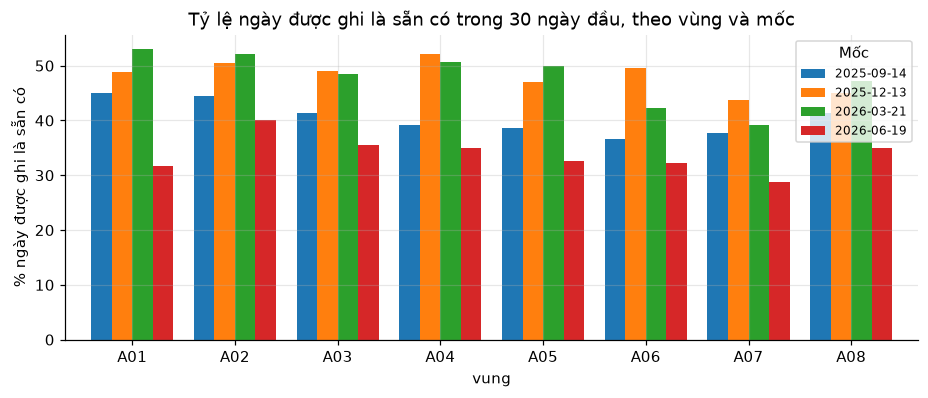

,2025-09-14,2025-12-13,2026-03-21,2026-06-19
vung,,,,
A01,45.0,48.9,53.0,31.7
A02,44.5,50.5,52.2,40.1
A03,41.3,49.1,48.4,35.6
A04,39.2,52.2,50.7,35.0
A05,38.6,47.1,49.9,32.6
A06,36.7,49.6,42.3,32.2
A07,37.7,43.7,39.1,28.8
A08,41.4,45.1,47.2,35.0


In [9]:
vung_cua_listing = phan_cong_listings.set_index("listing_id")["analysis_area"]
cac_dong = {}
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot, lich in lich_nhom.items():
    ngay = pd.to_datetime(lich["date"])
    # transform("min") trả ngày đầu tiên của listing về từng dòng lịch (Bài 5).
    ngay_dau = ngay.groupby(lich["listing_id"]).transform("min")
    trong_30_ngay = lich.loc[(ngay - ngay_dau).dt.days < 30]
    cac_dong[snapshot] = (trong_30_ngay.assign(vung=trong_30_ngay["listing_id"].map(vung_cua_listing),
                                                trong=trong_30_ngay["available"].eq("t"))
                          .groupby("vung")["trong"].mean() * 100)

bang_vung = pd.DataFrame(cac_dong).round(1)
bang_vung.plot(kind="bar", figsize=(10, 3.6), rot=0, width=0.8)
plt.ylabel("% ngày được ghi là sẵn có")
plt.title("Tỷ lệ ngày được ghi là sẵn có trong 30 ngày đầu, theo vùng và mốc")
plt.legend(title="Mốc", fontsize=8)
plt.show()
bang_vung

Đây là tỷ lệ ngày được ghi là sẵn có trong 30 ngày đầu. Chênh lệch giữa các mốc lớn hơn chênh lệch giữa các vùng. Cùng một vùng có thể dao động hơn 20 điểm phần trăm giữa các mốc, trong khi ở cùng
một mốc, các vùng chỉ cách nhau khoảng 8 đến 14 điểm. Ở mốc 2026-06-19, mọi vùng đều có tỷ lệ thấp hơn so với hai mốc tháng 12 và tháng 3.
Vì vậy, khi so sánh các vùng, cần so trong cùng một mốc, vì phần chênh lệch giữa các mốc tác động lên mọi vùng cùng lúc.

Dù vậy, A07 (vùng phía bắc trung tâm, gồm phần lớn Islington và Camden) có tỷ lệ thấp nhất ở ba trong bốn mốc. Đây là một khác biệt
lặp lại qua nhiều mốc chứ không phải dao động của riêng một mốc, nên đáng để nhóm xem tiếp khi chọn KPI theo vùng.

Phần còn lại của dữ liệu là nội dung review. Notebook 04 xem 5.000 review được giao trước khi chúng được gửi cho LLM.